# Notebook 4 — Expériences Images & Vision

**Objectif** : Benchmarker toutes les approches vision de l'équipe et générer des probabilités  
OOF (Out-Of-Fold) propres pour le stacking final.

**Modèles** :
1. **DINOv2** (backbone gelé, vit-base) — features 768-d mis en cache
2. **CLIP ViT-B/32** (backbone gelé, laion2b) — embeddings image 512-d mis en cache
3. **ResNet50** fine-tuning progressif en 3 phases (Xavier)
4. **DINOv2 Fine-Tuning** différentiel par blocs

**Interprétabilité** : GradCAM sur le meilleur modèle fine-tuné.

**Livrables** :
- `data/processed_clean/X_dino_*.npy` — features DINOv2 gelées
- `data/processed_clean/X_clip_*.npy` — embeddings CLIP
- `data/processed_clean/P_image_oof_train.npy` / `P_image_val.npy` / `P_image_test.npy`
- `models/clean/dino_ft_best.pth` — checkpoint du meilleur modèle image

---

## 0. Configuration

In [1]:
import os
os.environ['KMP_DUPLICATE_LIB_OK'] = 'TRUE'
os.environ['OMP_NUM_THREADS'] = '1'

from pathlib import Path

_NB_DIR = Path('__file__').resolve().parent if '__file__' in dir() else Path.cwd()
ROOT = _NB_DIR
for _ in range(5):
    if (ROOT / 'data' / 'raw').exists():
        break
    ROOT = ROOT.parent

CFG = {
    'root':        ROOT,
    'split_dir':   ROOT / 'data' / 'split_no_crop2',
    'crop_dir':    ROOT / 'data' / 'processed_clean' / 'image_crop',
    'processed':   ROOT / 'data' / 'processed_clean',
    'models_dir':  ROOT / 'models' / 'clean',
    'figures_dir': ROOT / 'reports' / 'figures',

    # OOF
    'n_folds':      5,
    'random_state': 42,
    'n_classes':    27,

    # DINOv2
    'dino_model':   'facebook/dinov2-base',
    'dino_dim':     768,
    'dino_batch':   64,

    # CLIP
    'clip_model':   'laion/CLIP-ViT-B-32-laion2B-s34B-b79K',
    'clip_dim':     512,
    'clip_batch':   64,

    # ResNet50 fine-tuning
    'resnet_batch':  32,
    'resnet_epochs': {'phase1': 3, 'phase2': 5, 'phase3': 5},
    'resnet_lr':     {'phase1': 1e-3, 'phase2': 1e-4, 'phase3': 1e-5},

    # DINOv2 fine-tuning
    'ft_epochs':     15,
    'ft_lr_head':    1e-3,
    'ft_lr_blk11':   5e-5,
    'ft_lr_blk10':   2e-5,
    'ft_warmup':     3,
    'ft_grad_clip':  1.0,
    'ft_mixup_alpha': 0.2,
    'ft_batch':      32,

    # Image preprocessing
    'img_size':      224,
    'imagenet_mean': [0.485, 0.456, 0.406],
    'imagenet_std':  [0.229, 0.224, 0.225],
}

for d in ['processed', 'models_dir', 'figures_dir']:
    CFG[d].mkdir(parents=True, exist_ok=True)

print(f'ROOT : {ROOT}')

ROOT : c:\Users\veyss\Nouveau dossier\nov25_alt1_mle_rakuten


## 1. Imports

In [2]:
%matplotlib inline
import pickle
import logging
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm.auto import tqdm

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, Dataset
import torchvision.transforms as T
import torchvision.models as tv_models

from PIL import Image
from transformers import AutoModel, AutoFeatureExtractor
from open_clip import create_model_and_transforms

from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import f1_score

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
logging.basicConfig(level=logging.INFO, format='%(asctime)s %(levelname)s %(message)s')
sns.set_theme(style='whitegrid')
print(f'Device : {device}')

def save_fig(name):
    plt.savefig(CFG['figures_dir'] / name, dpi=150, bbox_inches='tight')

Device : cuda


## 2. Chargement des données

In [3]:
train_df = pd.read_csv(CFG['split_dir'] / 'train.csv')
val_df   = pd.read_csv(CFG['split_dir'] / 'val.csv')
test_df  = pd.read_csv(CFG['split_dir'] / 'test.csv')

y_train = np.load(CFG['processed'] / 'y_train.npy')
y_val   = np.load(CFG['processed'] / 'y_val.npy')
y_test  = np.load(CFG['processed'] / 'y_test.npy')

class_weights = np.load(CFG['processed'] / 'class_weights.npy')
class_weights_tensor = torch.tensor(class_weights, dtype=torch.float32).to(device)

print(f'Train : {len(train_df):,}  Val : {len(val_df):,}  Test : {len(test_df):,}')

Train : 59,441  Val : 12,737  Test : 12,738


## 3. Dataset PyTorch — ImageDataset

In [4]:
transform_train = T.Compose([
    T.Resize((CFG['img_size'], CFG['img_size'])),
    T.RandomHorizontalFlip(),
    T.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2),
    T.ToTensor(),
    T.Normalize(mean=CFG['imagenet_mean'], std=CFG['imagenet_std']),
])

transform_eval = T.Compose([
    T.Resize((CFG['img_size'], CFG['img_size'])),
    T.ToTensor(),
    T.Normalize(mean=CFG['imagenet_mean'], std=CFG['imagenet_std']),
])


class ImageDataset(Dataset):
    def __init__(self, df: pd.DataFrame, img_dir: Path, labels: np.ndarray,
                 transform=None):
        self.df = df.reset_index(drop=True)
        self.img_dir = img_dir
        self.labels = labels
        self.transform = transform or transform_eval

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        img_name = self.df.loc[idx, 'image_name']
        path = self.img_dir / str(img_name)
        try:
            img = Image.open(path).convert('RGB')
        except Exception:
            img = Image.new('RGB', (CFG['img_size'], CFG['img_size']), color=(128, 128, 128))
        img = self.transform(img)
        label = int(self.labels[idx])
        return img, label

print('ImageDataset defini.')

ImageDataset defini.


---
## 4. Feature Extraction — DINOv2 (backbone gelé)

DINOv2-base produit un vecteur de 768 dimensions (token [CLS]).  
Le backbone est **entièrement gelé** — on extrait uniquement les features.

In [5]:
def extract_features_dino(
    df: pd.DataFrame,
    img_dir: Path,
    labels: np.ndarray,
    model,
    feature_extractor,
    batch_size: int = 64,
    name: str = '',
) -> np.ndarray:
    """Extrait les features DINOv2 [CLS] en mode inference."""
    dataset = ImageDataset(df, img_dir, labels, transform=transform_eval)
    loader = DataLoader(dataset, batch_size=batch_size, num_workers=0, pin_memory=True)

    model.eval()
    feats = []
    with torch.no_grad():
        for imgs, _ in tqdm(loader, desc=f'DINOv2 {name}'):
            imgs = imgs.to(device)
            out = model(pixel_values=imgs)
            cls_token = out.last_hidden_state[:, 0, :]  # [CLS]
            feats.append(cls_token.cpu().float().numpy())
    return np.vstack(feats)

In [6]:
DINO_TRAIN_CACHE = CFG['processed'] / 'X_dino_train.npy'

if DINO_TRAIN_CACHE.exists():
    X_dino_train = np.load(CFG['processed'] / 'X_dino_train.npy')
    X_dino_val   = np.load(CFG['processed'] / 'X_dino_val.npy')
    X_dino_test  = np.load(CFG['processed'] / 'X_dino_test.npy')
    print(f'DINOv2 features chargees depuis cache : {X_dino_train.shape}')
else:
    print(f'Chargement DINOv2 : {CFG["dino_model"]}')
    from transformers import AutoImageProcessor
    dino_proc  = AutoImageProcessor.from_pretrained(CFG['dino_model'])
    dino_model = AutoModel.from_pretrained(CFG['dino_model']).to(device)
    for p in dino_model.parameters():
        p.requires_grad = False

    X_dino_train = extract_features_dino(train_df, CFG['split_dir']/'train', y_train,
                                          dino_model, dino_proc, CFG['dino_batch'], 'Train')
    X_dino_val   = extract_features_dino(val_df,   CFG['split_dir']/'val',   y_val,
                                          dino_model, dino_proc, CFG['dino_batch'], 'Val')
    X_dino_test  = extract_features_dino(test_df,  CFG['split_dir']/'test',  y_test,
                                          dino_model, dino_proc, CFG['dino_batch'], 'Test')

    np.save(CFG['processed'] / 'X_dino_train.npy', X_dino_train)
    np.save(CFG['processed'] / 'X_dino_val.npy',   X_dino_val)
    np.save(CFG['processed'] / 'X_dino_test.npy',  X_dino_test)
    del dino_model
    torch.cuda.empty_cache() if torch.cuda.is_available() else None
    print(f'DINOv2 sauvegardes : {X_dino_train.shape}')

DINOv2 features chargees depuis cache : (59441, 768)


---
## 5. Feature Extraction — CLIP ViT-B/32 (backbone gelé)

In [7]:
CLIP_TRAIN_CACHE = CFG['processed'] / 'X_clip_train.npy'

if CLIP_TRAIN_CACHE.exists():
    X_clip_train = np.load(CFG['processed'] / 'X_clip_train.npy')
    X_clip_val   = np.load(CFG['processed'] / 'X_clip_val.npy')
    X_clip_test  = np.load(CFG['processed'] / 'X_clip_test.npy')
    print(f'CLIP features chargees depuis cache : {X_clip_train.shape}')
else:
    print('Chargement CLIP ViT-B/32 (laion2b)...')
    clip_model, _, clip_preprocess = create_model_and_transforms(
        'ViT-B-32', pretrained='laion2b_s34b_b79k'
    )
    clip_model = clip_model.to(device).eval()
    for p in clip_model.parameters():
        p.requires_grad = False

    def extract_clip_features(df, img_dir, labels, batch_size=64, name=''):
        dataset = ImageDataset(df, img_dir, labels, transform=clip_preprocess)
        loader  = DataLoader(dataset, batch_size=batch_size, num_workers=0)
        feats   = []
        with torch.no_grad():
            for imgs, _ in tqdm(loader, desc=f'CLIP {name}'):
                imgs = imgs.to(device)
                embs = clip_model.encode_image(imgs)
                embs = F.normalize(embs, dim=-1)
                feats.append(embs.cpu().float().numpy())
        return np.vstack(feats)

    X_clip_train = extract_clip_features(train_df, CFG['split_dir']/'train', y_train, CFG['clip_batch'], 'Train')
    X_clip_val   = extract_clip_features(val_df,   CFG['split_dir']/'val',   y_val,   CFG['clip_batch'], 'Val')
    X_clip_test  = extract_clip_features(test_df,  CFG['split_dir']/'test',  y_test,  CFG['clip_batch'], 'Test')

    np.save(CFG['processed'] / 'X_clip_train.npy', X_clip_train)
    np.save(CFG['processed'] / 'X_clip_val.npy',   X_clip_val)
    np.save(CFG['processed'] / 'X_clip_test.npy',  X_clip_test)
    del clip_model
    torch.cuda.empty_cache() if torch.cuda.is_available() else None
    print(f'CLIP sauvegardes : {X_clip_train.shape}')

CLIP features chargees depuis cache : (59441, 512)


---
## 6. Benchmark Frozen Features + MLP OOF

On évalue DINOv2 et CLIP en mode backbone gelé avec une tête MLP — mode OOF.  
Le MLP (avec early stopping) surpasse LogReg sur les features denses (cf. NB3 T4 vs T3).

In [8]:
# ── MLPClassifier (sklearn interface, early stopping) ──────────────────────────
class _MLP(nn.Module):
    def __init__(self, in_dim, n_classes=27, hidden=512, dropout=0.3):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(in_dim, hidden), nn.BatchNorm1d(hidden), nn.GELU(), nn.Dropout(dropout),
            nn.Linear(hidden, hidden // 2), nn.BatchNorm1d(hidden // 2), nn.GELU(), nn.Dropout(dropout),
            nn.Linear(hidden // 2, n_classes),
        )
    def forward(self, x):
        return self.net(x)


class MLPClassifier:
    """Wrapper sklearn : MLP PyTorch avec early stopping sur un val set."""

    def __init__(self, in_dim, n_classes=27, hidden=512, dropout=0.3,
                 lr=3e-4, batch_size=256, max_epochs=50, patience=5):
        self.in_dim = in_dim
        self.n_classes = n_classes
        self.hidden = hidden
        self.dropout = dropout
        self.lr = lr
        self.batch_size = batch_size
        self.max_epochs = max_epochs
        self.patience = patience

    def fit(self, X_tr, y_tr, X_vl=None, y_vl=None):
        model = _MLP(self.in_dim, self.n_classes, self.hidden, self.dropout).to(device)
        opt = torch.optim.Adam(model.parameters(), lr=self.lr)
        crit = nn.CrossEntropyLoss()

        X_t = torch.tensor(X_tr, dtype=torch.float32)
        y_t = torch.tensor(y_tr, dtype=torch.long)
        ds = torch.utils.data.TensorDataset(X_t, y_t)
        loader = torch.utils.data.DataLoader(ds, batch_size=self.batch_size, shuffle=True)

        best_loss, wait, best_state = np.inf, 0, None
        for epoch in range(self.max_epochs):
            model.train()
            for xb, yb in loader:
                xb, yb = xb.to(device), yb.to(device)
                opt.zero_grad()
                crit(model(xb), yb).backward()
                opt.step()

            if X_vl is not None:
                model.eval()
                with torch.no_grad():
                    xv = torch.tensor(X_vl, dtype=torch.float32).to(device)
                    yv = torch.tensor(y_vl, dtype=torch.long).to(device)
                    val_loss = crit(model(xv), yv).item()
                if val_loss < best_loss:
                    best_loss = val_loss
                    wait = 0
                    best_state = {k: v.clone() for k, v in model.state_dict().items()}
                else:
                    wait += 1
                    if wait >= self.patience:
                        break

        if best_state is not None:
            model.load_state_dict(best_state)
        self._model = model

    def predict_proba(self, X):
        self._model.eval()
        with torch.no_grad():
            xt = torch.tensor(X, dtype=torch.float32).to(device)
            logits = self._model(xt)
            return torch.softmax(logits, dim=1).cpu().numpy()


# ── run_oof (dense numpy, early stopping via try/except) ──────────────────────
def run_oof(X_train, y_train, X_val, X_test, clf_factory,
            n_folds=5, n_classes=27, name='model'):
    skf = StratifiedKFold(n_splits=n_folds, shuffle=True, random_state=42)
    n_train = X_train.shape[0]
    n_val   = X_val.shape[0]
    n_test  = X_test.shape[0]
    P_oof   = np.zeros((n_train, n_classes), dtype=np.float32)
    P_val_f = np.zeros((n_val,   n_classes), dtype=np.float32)
    P_tst_f = np.zeros((n_test,  n_classes), dtype=np.float32)
    f1s = []
    for fold, (tr_idx, vl_idx) in enumerate(skf.split(X_train, y_train)):
        clf = clf_factory()
        X_tr, y_tr = X_train[tr_idx], y_train[tr_idx]
        X_vl, y_vl = X_train[vl_idx], y_train[vl_idx]
        try:
            clf.fit(X_tr, y_tr, X_vl, y_vl)   # MLPClassifier : early stopping
        except TypeError:
            clf.fit(X_tr, y_tr)                # fallback sklearn
        oof_p = clf.predict_proba(X_vl)
        P_oof[vl_idx] += oof_p
        P_val_f += clf.predict_proba(X_val)
        P_tst_f += clf.predict_proba(X_test)
        f1s.append(f1_score(y_vl, oof_p.argmax(1), average='weighted'))
        print(f'    fold {fold+1}/{n_folds}  f1={f1s[-1]:.4f}')
    P_val_f /= n_folds
    P_tst_f /= n_folds
    f1_oof = f1_score(y_train, P_oof.argmax(1), average='weighted')
    f1_v   = f1_score(y_val,   P_val_f.argmax(1), average='weighted')
    f1_t   = f1_score(y_test,  P_tst_f.argmax(1), average='weighted')
    print(f'  [{name}] OOF={f1_oof:.4f}  Val={f1_v:.4f}  Test={f1_t:.4f}  '
          f'mean_fold={np.mean(f1s):.4f} ± {np.std(f1s):.4f}')
    return P_oof, P_val_f, P_tst_f


# ── Configs : MLP sur features DINOv2 (768-d) et CLIP (512-d) ─────────────────
def make_mlp_factory(in_dim):
    return lambda: MLPClassifier(in_dim=in_dim, n_classes=CFG['n_classes'],
                                 hidden=512, dropout=0.3, lr=3e-4,
                                 batch_size=256, max_epochs=50, patience=5)

img_configs = [
    ('I1_dino_mlp',  X_dino_train, X_dino_val, X_dino_test, make_mlp_factory(CFG['dino_dim'])),
    ('I2_clip_mlp',  X_clip_train, X_clip_val, X_clip_test, make_mlp_factory(CFG['clip_dim'])),
]

bench_img = []
for name, X_tr, X_vl, X_te, factory in img_configs:
    cache_p = CFG['processed'] / f'P_{name}_oof_train.npy'
    if cache_p.exists():
        P_o = np.load(str(CFG['processed'] / f'P_{name}_oof_train.npy'))
        P_v = np.load(str(CFG['processed'] / f'P_{name}_val.npy'))
        P_t = np.load(str(CFG['processed'] / f'P_{name}_test.npy'))
        f1_oof = f1_score(y_train, P_o.argmax(1), average='weighted')
        f1_v   = f1_score(y_val,   P_v.argmax(1), average='weighted')
        f1_t   = f1_score(y_test,  P_t.argmax(1), average='weighted')
        print(f'[CACHE] {name}  OOF={f1_oof:.4f}  Val={f1_v:.4f}  Test={f1_t:.4f}')
    else:
        print(f'\n=== {name} ===')
        P_o, P_v, P_t = run_oof(X_tr, y_train, X_vl, X_te, factory,
                                 n_folds=CFG['n_folds'], n_classes=CFG['n_classes'], name=name)
        np.save(CFG['processed'] / f'P_{name}_oof_train.npy', P_o)
        np.save(CFG['processed'] / f'P_{name}_val.npy',       P_v)
        np.save(CFG['processed'] / f'P_{name}_test.npy',      P_t)
        f1_oof = f1_score(y_train, P_o.argmax(1), average='weighted')
        f1_v   = f1_score(y_val,   P_v.argmax(1), average='weighted')
        f1_t   = f1_score(y_test,  P_t.argmax(1), average='weighted')

    bench_img.append({'Config': name, 'F1_OOF': round(f1_oof, 4),
                      'F1_Val': round(f1_v, 4), 'F1_Test': round(f1_t, 4)})

[CACHE] I1_dino_mlp  OOF=0.6901  Val=0.7092  Test=0.7051
[CACHE] I2_clip_mlp  OOF=0.7430  Val=0.7577  Test=0.7486


In [9]:
# ── 6.1 Variante Images Recadrées (Crop) — DINOv2 MLP OOF ────────────────────
# Même pipeline que I1_dino_mlp, sur les images autocadrées (image_crop/).
# Permet de mesurer l'impact du recadrage dans le stacking (cf. NB5 E8).

DINO_CROP_TRAIN_CACHE = CFG['processed'] / 'X_dino_crop_train.npy'

if DINO_CROP_TRAIN_CACHE.exists():
    X_dino_crop_train = np.load(CFG['processed'] / 'X_dino_crop_train.npy')
    X_dino_crop_val   = np.load(CFG['processed'] / 'X_dino_crop_val.npy')
    X_dino_crop_test  = np.load(CFG['processed'] / 'X_dino_crop_test.npy')
    print(f'DINOv2 crop features depuis cache : {X_dino_crop_train.shape}')
else:
    print('Extraction DINOv2 sur images recadrees...')
    from transformers import AutoModel, AutoImageProcessor
    dino_proc_c  = AutoImageProcessor.from_pretrained(CFG['dino_model'])
    dino_model_c = AutoModel.from_pretrained(CFG['dino_model']).to(device)
    for p in dino_model_c.parameters():
        p.requires_grad = False

    # image_crop/ est un dossier plat — tous les splits utilisent le même répertoire
    X_dino_crop_train = extract_features_dino(
        train_df, CFG['crop_dir'], y_train, dino_model_c, dino_proc_c,
        CFG['dino_batch'], 'Crop-Train')
    X_dino_crop_val   = extract_features_dino(
        val_df,   CFG['crop_dir'], y_val,   dino_model_c, dino_proc_c,
        CFG['dino_batch'], 'Crop-Val')
    X_dino_crop_test  = extract_features_dino(
        test_df,  CFG['crop_dir'], y_test,  dino_model_c, dino_proc_c,
        CFG['dino_batch'], 'Crop-Test')

    np.save(CFG['processed'] / 'X_dino_crop_train.npy', X_dino_crop_train)
    np.save(CFG['processed'] / 'X_dino_crop_val.npy',   X_dino_crop_val)
    np.save(CFG['processed'] / 'X_dino_crop_test.npy',  X_dino_crop_test)
    del dino_model_c
    if torch.cuda.is_available(): torch.cuda.empty_cache()
    print(f'DINOv2 crop sauvegardes : {X_dino_crop_train.shape}')

# OOF MLP sur DINOv2 crop features
CROP_OOF_CACHE = CFG['processed'] / 'P_I3_dino_crop_oof_train.npy'
if CROP_OOF_CACHE.exists():
    P_I3_oof = np.load(CFG['processed'] / 'P_I3_dino_crop_oof_train.npy')
    P_I3_val = np.load(CFG['processed'] / 'P_I3_dino_crop_val.npy')
    P_I3_tst = np.load(CFG['processed'] / 'P_I3_dino_crop_test.npy')
    print(f'[CACHE] I3_dino_crop  Val={f1_score(y_val, P_I3_val.argmax(1), average="weighted"):.4f}')
else:
    print('\n=== I3_dino_crop ===')
    P_I3_oof, P_I3_val, P_I3_tst = run_oof(
        X_dino_crop_train, y_train, X_dino_crop_val, X_dino_crop_test,
        make_mlp_factory(CFG['dino_dim']),
        n_folds=CFG['n_folds'], n_classes=CFG['n_classes'], name='I3_dino_crop'
    )
    np.save(CFG['processed'] / 'P_I3_dino_crop_oof_train.npy', P_I3_oof)
    np.save(CFG['processed'] / 'P_I3_dino_crop_val.npy',       P_I3_val)
    np.save(CFG['processed'] / 'P_I3_dino_crop_test.npy',      P_I3_tst)

bench_img.append({
    'Config':  'I3_dino_crop',
    'F1_OOF':  round(f1_score(y_train, P_I3_oof.argmax(1), average='weighted'), 4),
    'F1_Val':  round(f1_score(y_val,   P_I3_val.argmax(1), average='weighted'), 4),
    'F1_Test': round(f1_score(y_test,  P_I3_tst.argmax(1), average='weighted'), 4),
})
print(f'I3_dino_crop : F1_Val={bench_img[-1]["F1_Val"]:.4f}  F1_Test={bench_img[-1]["F1_Test"]:.4f}')

Extraction DINOv2 sur images recadrees...


DINOv2 Crop-Test: 100%|██████████| 200/200 [04:04<00:00,  1.22s/it]


DINOv2 crop sauvegardes : (59441, 768)

=== I3_dino_crop ===
    fold 1/5  f1=0.6944
    fold 2/5  f1=0.6917
    fold 3/5  f1=0.6928
    fold 4/5  f1=0.6910
    fold 5/5  f1=0.7004
  [I3_dino_crop] OOF=0.6942  Val=0.7131  Test=0.7073  mean_fold=0.6941 ± 0.0034
I3_dino_crop : F1_Val=0.7131  F1_Test=0.7073


---
## 7. ResNet50 — Fine-Tuning Progressif (3 Phases)

Stratégie Xavier :
- **Phase 1** : Seule la tête FC est entraînée (backbone gelé)
- **Phase 2** : Dégel des 2 derniers blocs (`layer4` + `layer3`)
- **Phase 3** : Dégel complet avec lr très faible

In [10]:
class ResNet50Classifier(nn.Module):
    def __init__(self, n_classes: int = 27, dropout: float = 0.3):
        super().__init__()
        backbone = tv_models.resnet50(weights=tv_models.ResNet50_Weights.IMAGENET1K_V2)
        in_features = backbone.fc.in_features
        backbone.fc = nn.Identity()
        self.backbone = backbone
        self.head = nn.Sequential(
            nn.Dropout(dropout),
            nn.Linear(in_features, 512),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Linear(512, n_classes),
        )

    def forward(self, x):
        return self.head(self.backbone(x))

    def freeze_backbone(self):
        for p in self.backbone.parameters():
            p.requires_grad = False

    def unfreeze_layers(self, layer_names: list):
        for name, module in self.backbone.named_children():
            if name in layer_names:
                for p in module.parameters():
                    p.requires_grad = True


def train_epoch(model, loader, optimizer, criterion, scaler=None):
    model.train()
    total_loss = 0
    for imgs, labels in loader:
        imgs, labels = imgs.to(device), labels.to(device)
        optimizer.zero_grad()
        if scaler:
            with torch.cuda.amp.autocast():
                loss = criterion(model(imgs), labels)
            scaler.scale(loss).backward()
            scaler.step(optimizer)
            scaler.update()
        else:
            loss = criterion(model(imgs), labels)
            loss.backward()
            optimizer.step()
        total_loss += loss.item()
    return total_loss / len(loader)


@torch.no_grad()
def eval_model(model, loader, n_classes=27) -> tuple:
    model.eval()
    all_preds, all_labels, all_probas = [], [], []
    for imgs, labels in loader:
        imgs = imgs.to(device)
        logits = model(imgs)
        probas = torch.softmax(logits, dim=1).cpu().numpy()
        all_probas.append(probas)
        all_preds.extend(probas.argmax(axis=1))
        all_labels.extend(labels.numpy())
    return (np.array(all_preds), np.array(all_labels),
            np.vstack(all_probas))

print('ResNet50Classifier et fonctions definies.')

ResNet50Classifier et fonctions definies.


In [11]:
RESNET_MODEL_PATH = CFG['models_dir'] / 'resnet50_ft.pth'
TRAIN_RESNET = not RESNET_MODEL_PATH.exists()

train_dataset  = ImageDataset(train_df, CFG['split_dir']/'train', y_train, transform_train)
val_dataset    = ImageDataset(val_df,   CFG['split_dir']/'val',   y_val,   transform_eval)
train_loader   = DataLoader(train_dataset, batch_size=CFG['resnet_batch'], shuffle=True,  num_workers=0)
val_loader     = DataLoader(val_dataset,   batch_size=CFG['resnet_batch'], shuffle=False, num_workers=0)

criterion = nn.CrossEntropyLoss(weight=class_weights_tensor)

if TRAIN_RESNET:
    resnet = ResNet50Classifier(n_classes=CFG['n_classes']).to(device)
    resnet.freeze_backbone()
    scaler = torch.cuda.amp.GradScaler() if torch.cuda.is_available() else None

    # Phase 1 : tete seulement
    print('\nResNet50 — Phase 1 (tete seulement)')
    opt = torch.optim.Adam(filter(lambda p: p.requires_grad, resnet.parameters()),
                           lr=CFG['resnet_lr']['phase1'])
    for ep in range(CFG['resnet_epochs']['phase1']):
        loss = train_epoch(resnet, train_loader, opt, criterion, scaler)
        preds, labels, _ = eval_model(resnet, val_loader)
        f1 = f1_score(labels, preds, average='weighted')
        print(f'  Ep {ep+1} loss={loss:.4f}  val_f1={f1:.4f}')

    # Phase 2 : degel layer4
    print('\nResNet50 — Phase 2 (layer4 + layer3 degelees)')
    resnet.unfreeze_layers(['layer4', 'layer3'])
    opt = torch.optim.Adam(filter(lambda p: p.requires_grad, resnet.parameters()),
                           lr=CFG['resnet_lr']['phase2'])
    best_f1_r, best_state_r = 0.0, None
    for ep in range(CFG['resnet_epochs']['phase2']):
        loss = train_epoch(resnet, train_loader, opt, criterion, scaler)
        preds, labels, _ = eval_model(resnet, val_loader)
        f1 = f1_score(labels, preds, average='weighted')
        print(f'  Ep {ep+1} loss={loss:.4f}  val_f1={f1:.4f}')
        if f1 > best_f1_r:
            best_f1_r = f1
            best_state_r = {k: v.clone() for k, v in resnet.state_dict().items()}

    # Phase 3 : degel complet
    print('\nResNet50 — Phase 3 (backbone complet)')
    for p in resnet.parameters(): p.requires_grad = True
    opt = torch.optim.Adam(resnet.parameters(), lr=CFG['resnet_lr']['phase3'])
    for ep in range(CFG['resnet_epochs']['phase3']):
        loss = train_epoch(resnet, train_loader, opt, criterion, scaler)
        preds, labels, _ = eval_model(resnet, val_loader)
        f1 = f1_score(labels, preds, average='weighted')
        print(f'  Ep {ep+1} loss={loss:.4f}  val_f1={f1:.4f}')
        if f1 > best_f1_r:
            best_f1_r = f1
            best_state_r = {k: v.clone() for k, v in resnet.state_dict().items()}

    resnet.load_state_dict(best_state_r)
    torch.save(resnet.state_dict(), RESNET_MODEL_PATH)
    print(f'ResNet50 sauvegarde : val_f1={best_f1_r:.4f}')
else:
    resnet = ResNet50Classifier(n_classes=CFG['n_classes']).to(device)
    resnet.load_state_dict(torch.load(RESNET_MODEL_PATH, map_location=device))
    _, val_labels, val_probas_r = eval_model(resnet, val_loader)
    best_f1_r = f1_score(val_labels, val_probas_r.argmax(1), average='weighted')
    print(f'ResNet50 charge : val_f1={best_f1_r:.4f}')

KeyboardInterrupt: 

---
## 8. DINOv2 Fine-Tuning — Dernier Bloc Seulement

**Architecture** : DINOv2-base + MLP head (768 → 512 → 256 → 27)  
**Stratégie** : seul le bloc 11 (dernier) est dégelé — head=1e-3, bloc11=5e-5  
**MixUp** (α=0.2) pour régularisation

In [12]:
class DINOv2Classifier(nn.Module):
    def __init__(self, backbone, n_classes: int = 27, hidden: int = 512, dropout: float = 0.3):
        super().__init__()
        self.backbone = backbone
        feat_dim = backbone.config.hidden_size
        self.head = nn.Sequential(
            nn.LayerNorm(feat_dim),
            nn.Linear(feat_dim, hidden),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Linear(hidden, hidden // 2),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Linear(hidden // 2, n_classes),
        )

    def forward(self, pixel_values):
        out = self.backbone(pixel_values=pixel_values)
        cls = out.last_hidden_state[:, 0, :]
        return self.head(cls)


def mixup_batch(imgs: torch.Tensor, labels: torch.Tensor, alpha: float = 0.2):
    """Applique MixUp sur un batch."""
    lam = np.random.beta(alpha, alpha) if alpha > 0 else 1.0
    idx = torch.randperm(imgs.size(0), device=imgs.device)
    mixed_imgs = lam * imgs + (1 - lam) * imgs[idx]
    return mixed_imgs, labels, labels[idx], lam


def mixup_loss(criterion, logits, y_a, y_b, lam):
    return lam * criterion(logits, y_a) + (1 - lam) * criterion(logits, y_b)

print('DINOv2Classifier et mixup definis.')

DINOv2Classifier et mixup definis.


In [13]:
DINO_FT_PATH = CFG['models_dir'] / 'dino_ft_best.pth'
TRAIN_DINO_FT = not DINO_FT_PATH.exists()

if TRAIN_DINO_FT:
    from transformers import AutoModel, AutoImageProcessor
    dino_proc     = AutoImageProcessor.from_pretrained(CFG['dino_model'])
    dino_backbone = AutoModel.from_pretrained(CFG['dino_model'])

    # Geler tout le backbone, puis dégeler uniquement le bloc 11 (dernier)
    for name, p in dino_backbone.named_parameters():
        p.requires_grad = False
    for name, p in dino_backbone.named_parameters():
        if 'encoder.layer.11' in name:
            p.requires_grad = True

    dino_ft = DINOv2Classifier(dino_backbone, CFG['n_classes']).to(device)

    param_groups = [
        {'params': dino_ft.head.parameters(), 'lr': CFG['ft_lr_head']},
        {'params': [p for n, p in dino_ft.backbone.named_parameters()
                    if 'encoder.layer.11' in n and p.requires_grad], 'lr': CFG['ft_lr_blk11']},
    ]
    opt = torch.optim.AdamW(param_groups, weight_decay=1e-4)

    from torch.optim.lr_scheduler import CosineAnnealingLR, LinearLR, SequentialLR
    warmup = LinearLR(opt, start_factor=0.1, end_factor=1.0, total_iters=CFG['ft_warmup'])
    cosine = CosineAnnealingLR(opt, T_max=CFG['ft_epochs'] - CFG['ft_warmup'])
    sched  = SequentialLR(opt, schedulers=[warmup, cosine], milestones=[CFG['ft_warmup']])

    criterion_ft = nn.CrossEntropyLoss(weight=class_weights_tensor)
    scaler_ft    = torch.cuda.amp.GradScaler() if torch.cuda.is_available() else None

    train_loader_ft = DataLoader(
        ImageDataset(train_df, CFG['split_dir']/'train', y_train, transform_train),
        batch_size=CFG['ft_batch'], shuffle=True, num_workers=0)
    val_loader_ft = DataLoader(
        ImageDataset(val_df, CFG['split_dir']/'val', y_val, transform_eval),
        batch_size=CFG['ft_batch'] * 2, shuffle=False, num_workers=0)

    best_f1_ft, best_state_ft = 0.0, None
    for epoch in range(CFG['ft_epochs']):
        dino_ft.train()
        ep_loss = 0
        for imgs, labels in tqdm(train_loader_ft, desc=f'DINOv2-FT ep{epoch+1}', leave=False):
            imgs, labels = imgs.to(device), labels.to(device)
            imgs_m, ya, yb, lam = mixup_batch(imgs, labels, CFG['ft_mixup_alpha'])
            opt.zero_grad()
            if scaler_ft:
                with torch.cuda.amp.autocast():
                    logits = dino_ft(imgs_m)
                    loss = mixup_loss(criterion_ft, logits, ya, yb, lam)
                scaler_ft.scale(loss).backward()
                scaler_ft.unscale_(opt)
                nn.utils.clip_grad_norm_(dino_ft.parameters(), CFG['ft_grad_clip'])
                scaler_ft.step(opt)
                scaler_ft.update()
            else:
                logits = dino_ft(imgs_m)
                loss = mixup_loss(criterion_ft, logits, ya, yb, lam)
                loss.backward()
                nn.utils.clip_grad_norm_(dino_ft.parameters(), CFG['ft_grad_clip'])
                opt.step()
            ep_loss += loss.item()

        sched.step()
        preds, labels_v, _ = eval_model(dino_ft, val_loader_ft)
        f1_v = f1_score(labels_v, preds, average='weighted')
        print(f'  Ep {epoch+1}/{CFG["ft_epochs"]} loss={ep_loss/len(train_loader_ft):.4f}  val_f1={f1_v:.4f}')
        if f1_v > best_f1_ft:
            best_f1_ft = f1_v
            best_state_ft = {k: v.clone() for k, v in dino_ft.state_dict().items()}

    dino_ft.load_state_dict(best_state_ft)
    torch.save(dino_ft.state_dict(), DINO_FT_PATH)
    print(f'DINOv2-FT sauvegarde : best_val_f1={best_f1_ft:.4f}')
else:
    from transformers import AutoModel
    dino_backbone = AutoModel.from_pretrained(CFG['dino_model'])
    dino_ft = DINOv2Classifier(dino_backbone, CFG['n_classes']).to(device)
    dino_ft.load_state_dict(torch.load(DINO_FT_PATH, map_location=device))
    dino_ft.eval()
    _vl = DataLoader(ImageDataset(val_df, CFG['split_dir']/'val', y_val, transform_eval),
                     batch_size=CFG['ft_batch']*2, shuffle=False, num_workers=0)
    _, _yl, _yp = eval_model(dino_ft, _vl)
    print(f'DINOv2-FT charge : val_f1={f1_score(_yl, _yp.argmax(1), average="weighted"):.4f}')

KeyboardInterrupt: 

---
## 9. CLIP ViT-B/32 — Fine-Tuning Différentiel (Dernier Bloc)

Même stratégie que DINOv2-FT : backbone gelé sauf le dernier bloc transformer.  
**Architecture** : CLIP visual encoder (ViT-B/32, 512-d) → MLP head (512 → 256 → 27)  
**LR différentiel** : head=1e-3, resblock[-1]=5e-5  
**MixUp** (α=0.2) + early stopping implicite via cosine scheduler

In [14]:
class CLIPFTClassifier(nn.Module):
    def __init__(self, visual, n_classes=27, feat_dim=512, hidden=512, dropout=0.3):
        super().__init__()
        self.visual = visual
        self.head = nn.Sequential(
            nn.LayerNorm(feat_dim),
            nn.Linear(feat_dim, hidden),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Linear(hidden, hidden // 2),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Linear(hidden // 2, n_classes),
        )

    def forward(self, x):
        return self.head(self.visual(x))


# Normalisation CLIP (différente d'ImageNet)
CLIP_MEAN = (0.48145466, 0.4578275, 0.40821073)
CLIP_STD  = (0.26862954, 0.26130258, 0.27577711)

transform_clip_train = T.Compose([
    T.Resize((224, 224)),
    T.RandomHorizontalFlip(),
    T.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2),
    T.ToTensor(),
    T.Normalize(mean=CLIP_MEAN, std=CLIP_STD),
])

transform_clip_eval = T.Compose([
    T.Resize((224, 224)),
    T.ToTensor(),
    T.Normalize(mean=CLIP_MEAN, std=CLIP_STD),
])

print('CLIPFTClassifier et transforms CLIP definis.')

CLIPFTClassifier et transforms CLIP definis.


In [ ]:
CLIP_FT_PATH = CFG['models_dir'] / 'clip_ft_best.pth'
TRAIN_CLIP_FT = not CLIP_FT_PATH.exists()

In [ ]:
if TRAIN_CLIP_FT:
    clip_ft_base, _, _ = create_model_and_transforms('ViT-B-32', pretrained='laion2b_s34b_b79k')
    clip_visual = clip_ft_base.visual.to(device)

    # Geler tout le visual encoder, puis dégeler uniquement le dernier resblock
    for p in clip_visual.parameters():
        p.requires_grad = False
    for p in clip_visual.transformer.resblocks[-1].parameters():
        p.requires_grad = True

    clip_ft = CLIPFTClassifier(clip_visual, CFG['n_classes']).to(device)

    param_groups = [
        {'params': clip_ft.head.parameters(),                          'lr': CFG['ft_lr_head']},
        {'params': clip_visual.transformer.resblocks[-1].parameters(), 'lr': CFG['ft_lr_blk11']},
    ]
    opt = torch.optim.AdamW(param_groups, weight_decay=1e-4)

    from torch.optim.lr_scheduler import CosineAnnealingLR, LinearLR, SequentialLR
    warmup = LinearLR(opt, start_factor=0.1, end_factor=1.0, total_iters=CFG['ft_warmup'])
    cosine = CosineAnnealingLR(opt, T_max=CFG['ft_epochs'] - CFG['ft_warmup'])
    sched  = SequentialLR(opt, schedulers=[warmup, cosine], milestones=[CFG['ft_warmup']])

    criterion_cft = nn.CrossEntropyLoss(weight=class_weights_tensor)
    scaler_cft    = torch.cuda.amp.GradScaler() if torch.cuda.is_available() else None

    train_loader_cft = DataLoader(
        ImageDataset(train_df, CFG['split_dir']/'train', y_train, transform_clip_train),
        batch_size=CFG['ft_batch'], shuffle=True, num_workers=0)
    val_loader_cft = DataLoader(
        ImageDataset(val_df, CFG['split_dir']/'val', y_val, transform_clip_eval),
        batch_size=CFG['ft_batch'] * 2, shuffle=False, num_workers=0)

    best_f1_cft, best_state_cft = 0.0, None
    for epoch in range(CFG['ft_epochs']):
        clip_ft.train()
        ep_loss = 0
        for imgs, labels in tqdm(train_loader_cft, desc=f'CLIP-FT ep{epoch+1}', leave=False):
            imgs, labels = imgs.to(device), labels.to(device)
            imgs_m, ya, yb, lam = mixup_batch(imgs, labels, CFG['ft_mixup_alpha'])
            opt.zero_grad()
            if scaler_cft:
                with torch.cuda.amp.autocast():
                    logits = clip_ft(imgs_m)
                    loss = mixup_loss(criterion_cft, logits, ya, yb, lam)
                scaler_cft.scale(loss).backward()
                scaler_cft.unscale_(opt)
                nn.utils.clip_grad_norm_(clip_ft.parameters(), CFG['ft_grad_clip'])
                scaler_cft.step(opt)
                scaler_cft.update()
            else:
                logits = clip_ft(imgs_m)
                loss = mixup_loss(criterion_cft, logits, ya, yb, lam)
                loss.backward()
                nn.utils.clip_grad_norm_(clip_ft.parameters(), CFG['ft_grad_clip'])
                opt.step()
            ep_loss += loss.item()

        sched.step()
        preds, labels_v, _ = eval_model(clip_ft, val_loader_cft)
        f1_v = f1_score(labels_v, preds, average='weighted')
        print(f'  Ep {epoch+1}/{CFG["ft_epochs"]}  loss={ep_loss/len(train_loader_cft):.4f}  val_f1={f1_v:.4f}')
        if f1_v > best_f1_cft:
            best_f1_cft = f1_v
            best_state_cft = {k: v.clone() for k, v in clip_ft.state_dict().items()}

    clip_ft.load_state_dict(best_state_cft)
    torch.save(clip_ft.state_dict(), CLIP_FT_PATH)
    print(f'CLIP-FT sauvegarde : best_val_f1={best_f1_cft:.4f}')
else:
    clip_ft_base, _, _ = create_model_and_transforms('ViT-B-32', pretrained='laion2b_s34b_b79k')
    clip_visual = clip_ft_base.visual.to(device)
    clip_ft = CLIPFTClassifier(clip_visual, CFG['n_classes']).to(device)
    clip_ft.load_state_dict(torch.load(CLIP_FT_PATH, map_location=device))
    clip_ft.eval()
    _vl = DataLoader(ImageDataset(val_df, CFG['split_dir']/'val', y_val, transform_clip_eval),
                     batch_size=CFG['ft_batch']*2, shuffle=False, num_workers=0)
    _, _yl, _yp = eval_model(clip_ft, _vl)
    print(f'CLIP-FT charge : val_f1={f1_score(_yl, _yp.argmax(1), average="weighted"):.4f}')

---
## 9. Interprétabilité — GradCAM

GradCAM sur ResNet50 : visualise les zones de l'image qui ont le plus influencé la décision.

In [34]:
class GradCAM:
    """GradCAM pour CNN (ResNet50)."""

    def __init__(self, model, target_layer):
        self.model = model
        self._activations = self._gradients = None
        target_layer.register_forward_hook(self._save_activation)
        target_layer.register_full_backward_hook(self._save_gradient)

    def _save_activation(self, _, __, output):
        self._activations = output.detach()

    def _save_gradient(self, _, __, grad_output):
        self._gradients = grad_output[0].detach()

    def generate(self, img_tensor, class_idx=None, forward_fn=None):
        self.model.eval()
        img = img_tensor.unsqueeze(0).to(device)
        logits = forward_fn(img) if forward_fn else self.model(img)
        if class_idx is None:
            class_idx = logits.argmax(dim=1).item()
        self.model.zero_grad()
        logits[:, class_idx].backward()
        weights = self._gradients.mean(dim=(2, 3), keepdim=True)
        cam = (weights * self._activations).sum(dim=1).squeeze()
        cam = F.relu(cam).cpu().numpy()
        cam -= cam.min()
        if cam.max() > 0:
            cam /= cam.max()
        return cam


class DINOAttnViz:
    """Attention CLS native DINOv2 (Oquab et al. 2023).
    Derniere couche, moyenne des tetes d attention CLS -> patches."""

    def __init__(self, model):
        self.model = model

    def generate(self, img_tensor, **kwargs):
        self.model.eval()
        with torch.no_grad():
            out = self.model.backbone(
                pixel_values=img_tensor.unsqueeze(0).to(device),
                output_attentions=True,
            )
        attn = out.attentions[-1][0]           # (n_heads, seq, seq)
        cls_attn = attn[:, 0, 1:].mean(0).cpu().numpy()  # (n_patches,)
        h = w = int(round(len(cls_attn) ** 0.5))
        cam = cls_attn.reshape(h, w)
        cam -= cam.min()
        if cam.max() > 0:
            cam /= cam.max()
        return cam


class CLIPRollout:
    """Attention Rollout pour CLIP ViT (Abnar & Zuidema, 2020).
    Accumule les matrices d attention sur toutes les couches :
        A_rollout = prod_l ( (A_l + I) / 2 )
    en patchant nn.MultiheadAttention.forward (pas la methode 'attention')
    pour eviter les conflits de signature open_clip.
    """

    def __init__(self, model):
        self.model = model
        self.blocks = model.visual.transformer.resblocks

    def generate(self, img_tensor, **kwargs):
        self.model.eval()
        _weights = {}

        # -- Patch attn.forward sur chaque bloc ----------------------------------
        _orig = {}
        for i, block in enumerate(self.blocks):
            _orig[i] = block.attn.forward  # bound method

            def _make(idx, orig_fn):
                def _p(*args, **kw):
                    kw['need_weights'] = True
                    try:
                        out, w = orig_fn(*args, **kw, average_attn_weights=False)
                        _weights[idx] = w.detach()   # (B, n_heads, seq, seq)
                    except TypeError:
                        kw.pop('average_attn_weights', None)
                        out, w = orig_fn(*args, **kw)
                        _weights[idx] = w.detach().unsqueeze(1)
                    return out, None  # nn.MultiheadAttention attend un tuple
                return _p

            block.attn.forward = _make(i, block.attn.forward)

        with torch.no_grad():
            _ = self.model(img_tensor.unsqueeze(0).to(device))

        for i, block in enumerate(self.blocks):
            block.attn.forward = _orig[i]

        # -- Rollout -------------------------------------------------------------
        seq = next(iter(_weights.values())).shape[-1]
        rollout = torch.eye(seq)

        for i in range(len(self.blocks)):
            if i not in _weights:
                continue
            A = _weights[i][0].mean(0).cpu()       # (seq, seq) moy tetes
            A = (A + torch.eye(seq)) / 2           # residuel
            A = A / A.sum(dim=-1, keepdim=True)    # normaliser lignes
            rollout = A @ rollout

        # CLS (index 0) -> patches (indices 1+)
        cls_row = rollout[0, 1:].numpy()
        h = w = int(round(len(cls_row) ** 0.5))
        cam = cls_row.reshape(h, w)
        cam -= cam.min()
        if cam.max() > 0:
            cam /= cam.max()
        return cam


def overlay_gradcam(original_img, cam):
    import matplotlib.cm as mpl_cm
    cam_uint8 = (cam * 255).astype(np.uint8)
    cam_resized = np.array(
        Image.fromarray(cam_uint8).resize(
            (original_img.width, original_img.height), Image.BILINEAR
        )
    ) / 255.0
    heatmap = (mpl_cm.jet(cam_resized)[:, :, :3] * 255).astype(np.uint8)
    img_arr = np.array(original_img.convert('RGB'))
    return (0.5 * img_arr + 0.5 * heatmap).astype(np.uint8)

print('GradCAM, DINOAttnViz, CLIPRollout, overlay_gradcam definis.')


GradCAM, DINOAttnViz, CLIPRollout, overlay_gradcam definis.


ResNet50   F1=0.6853


2026-05-18 19:50:10,296 INFO Parsing model identifier. Schema: None, Identifier: ViT-B-32
2026-05-18 19:50:10,296 INFO Loaded built-in ViT-B-32 model config.


DINOv2-FT  F1=0.7438


2026-05-18 19:50:10,530 INFO Instantiating model architecture: CLIP
2026-05-18 19:50:11,175 INFO Loading full pretrained weights from: C:\Users\veyss\.cache\huggingface\hub\models--laion--CLIP-ViT-B-32-laion2B-s34B-b79K\snapshots\1a25a446712ba5ee05982a381eed697ef9b435cf\open_clip_model.safetensors
2026-05-18 19:50:11,408 INFO Final image preprocessing configuration set: {'size': (224, 224), 'mode': 'RGB', 'mean': (0.48145466, 0.4578275, 0.40821073), 'std': (0.26862954, 0.26130258, 0.27577711), 'interpolation': 'bicubic', 'resize_mode': 'shortest', 'fill_color': 0}
2026-05-18 19:50:11,409 INFO Model ViT-B-32 creation process complete.


CLIP-FT    F1=0.7579


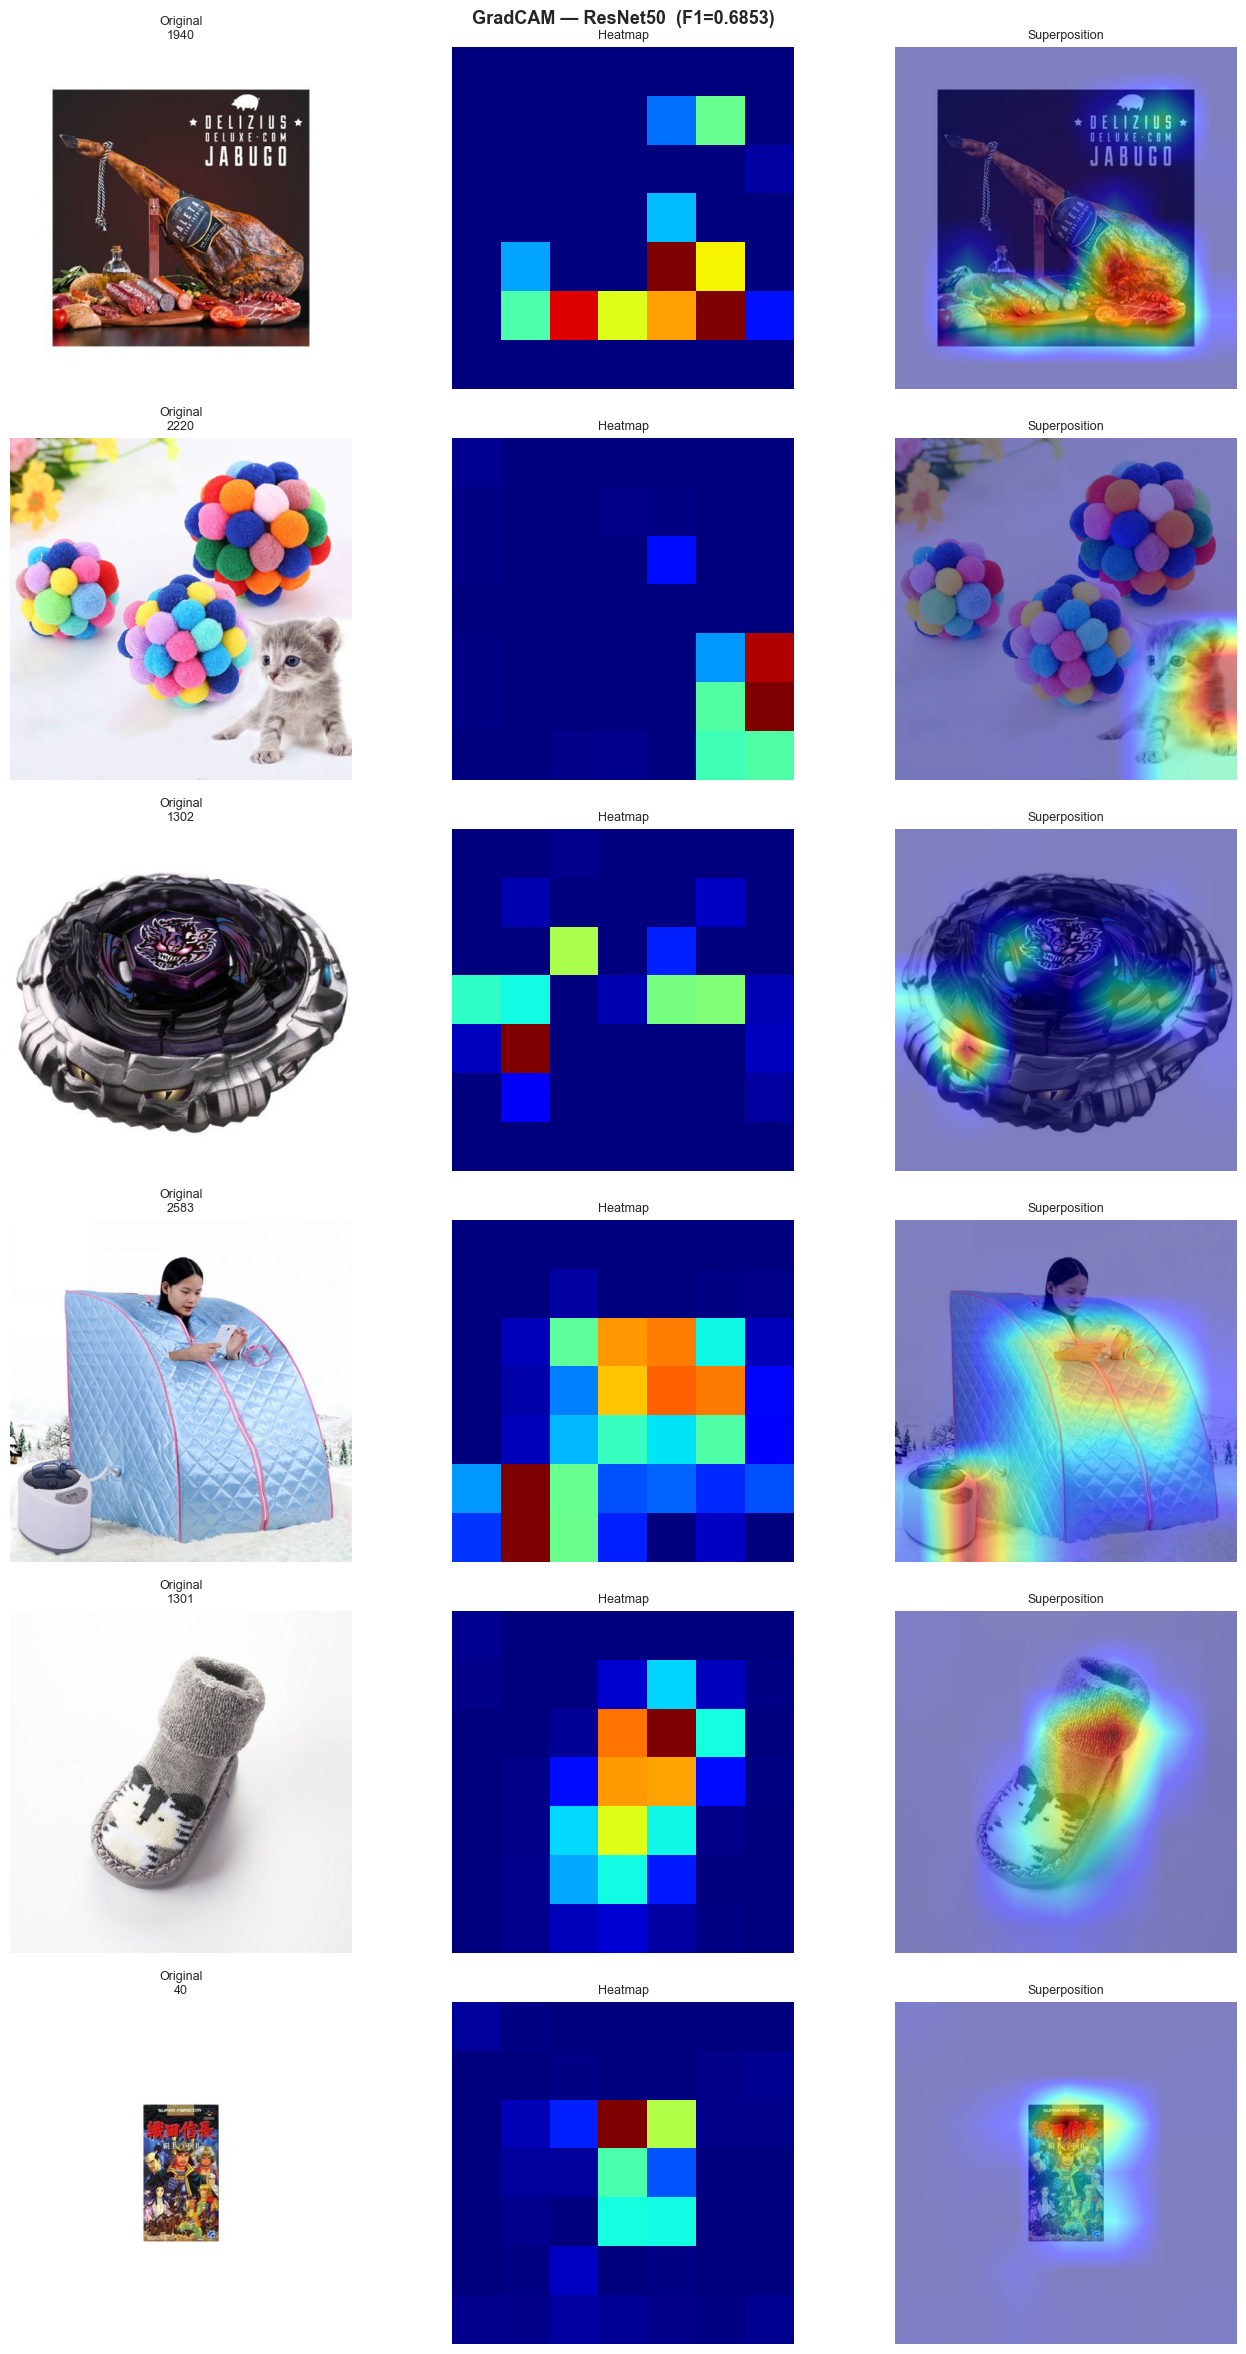

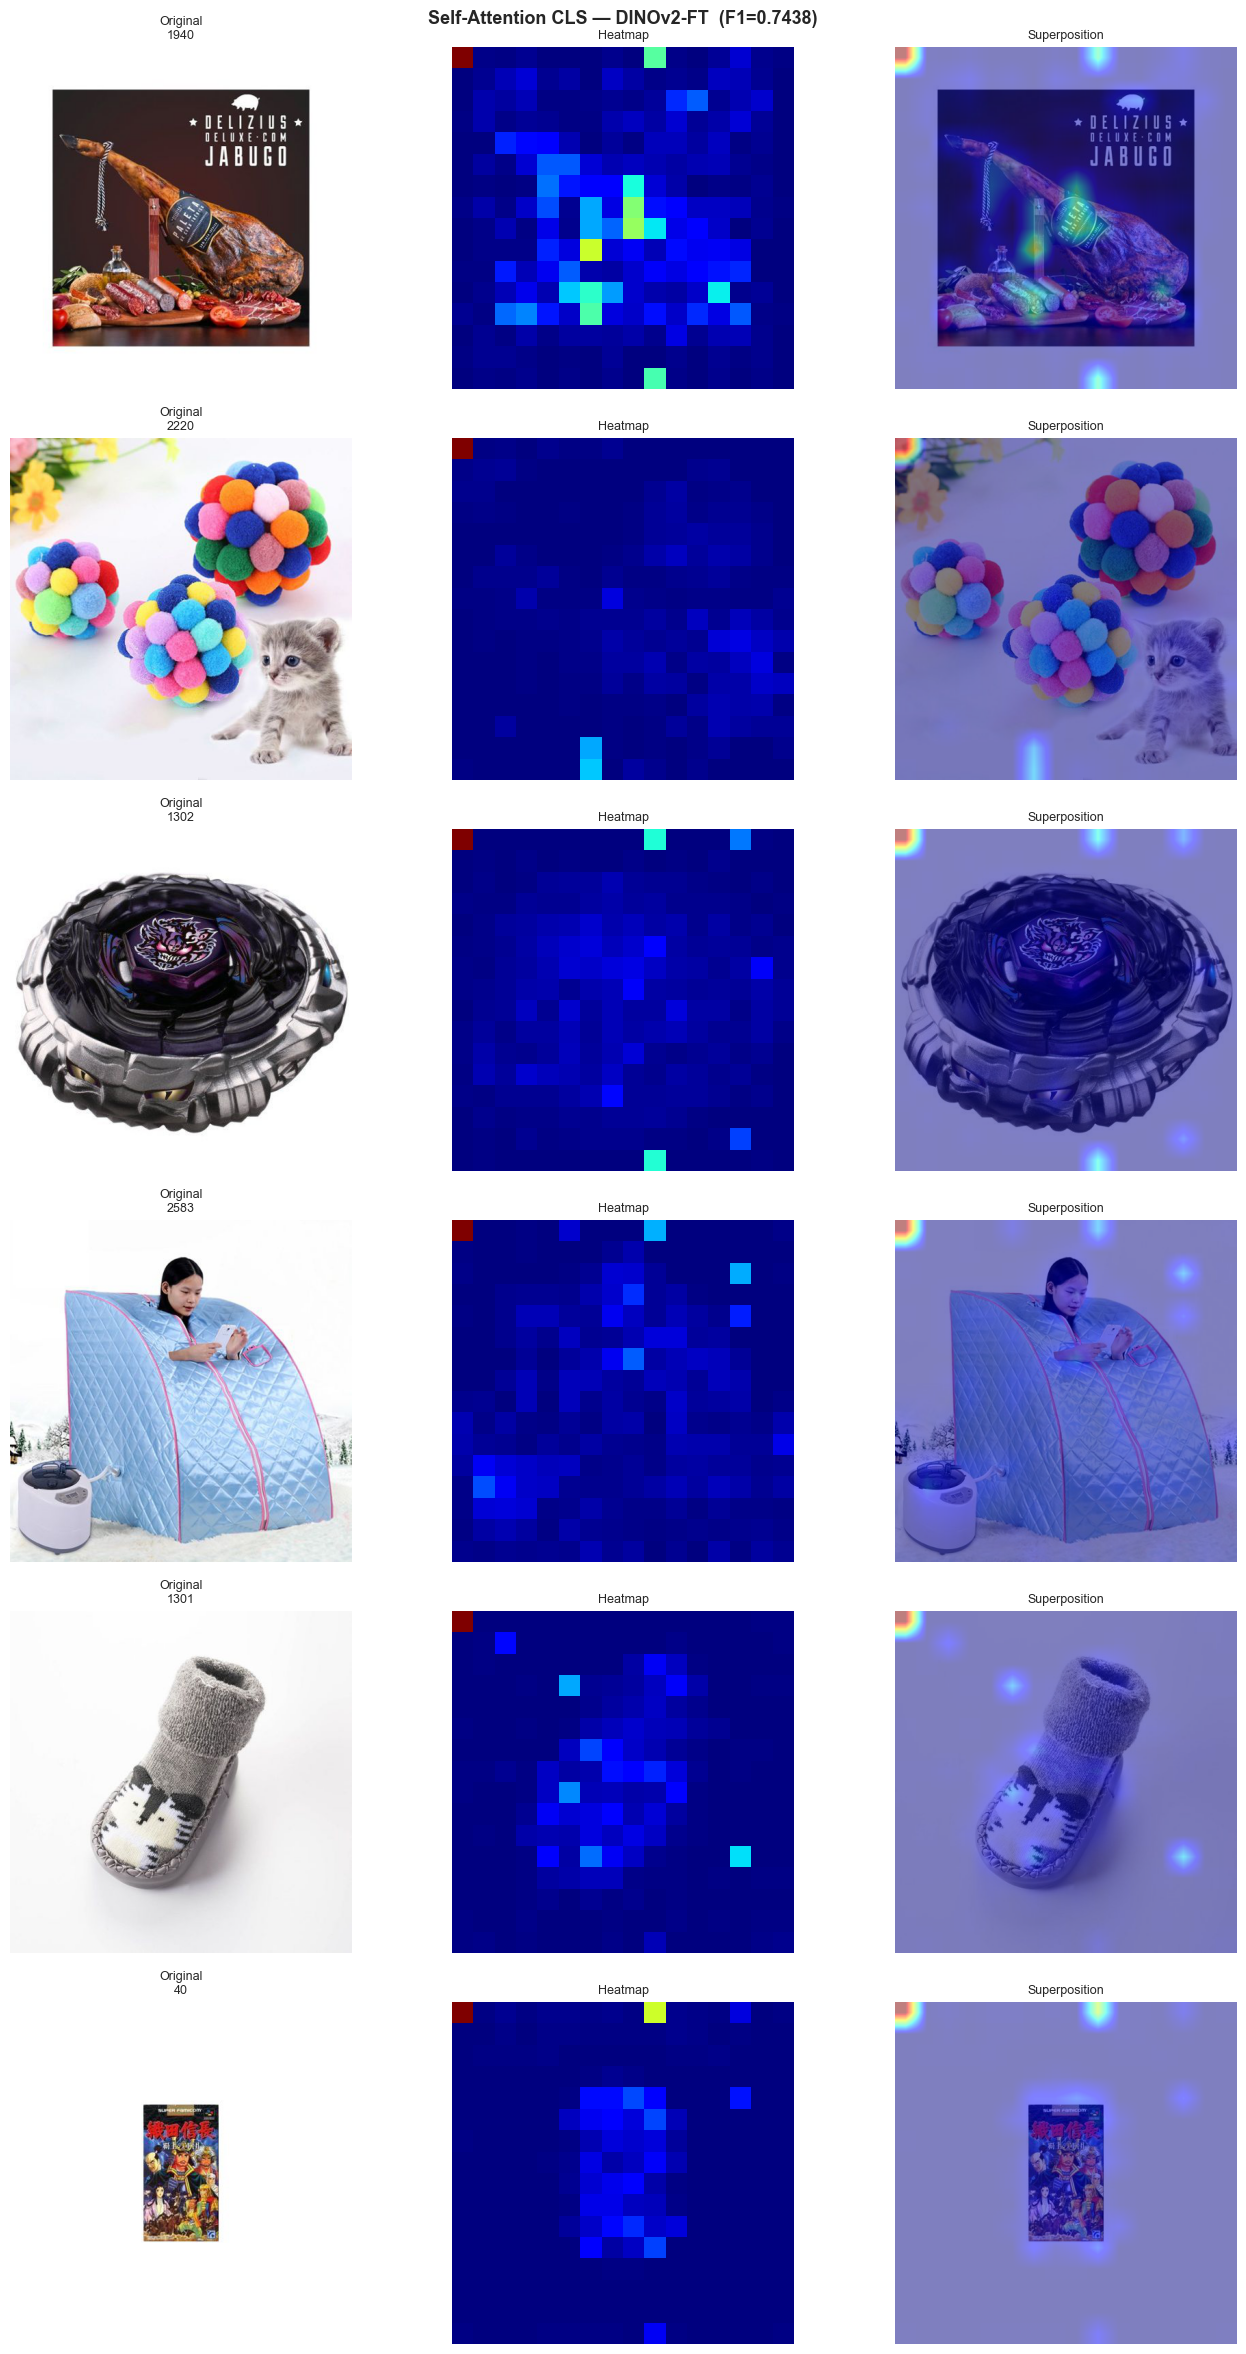

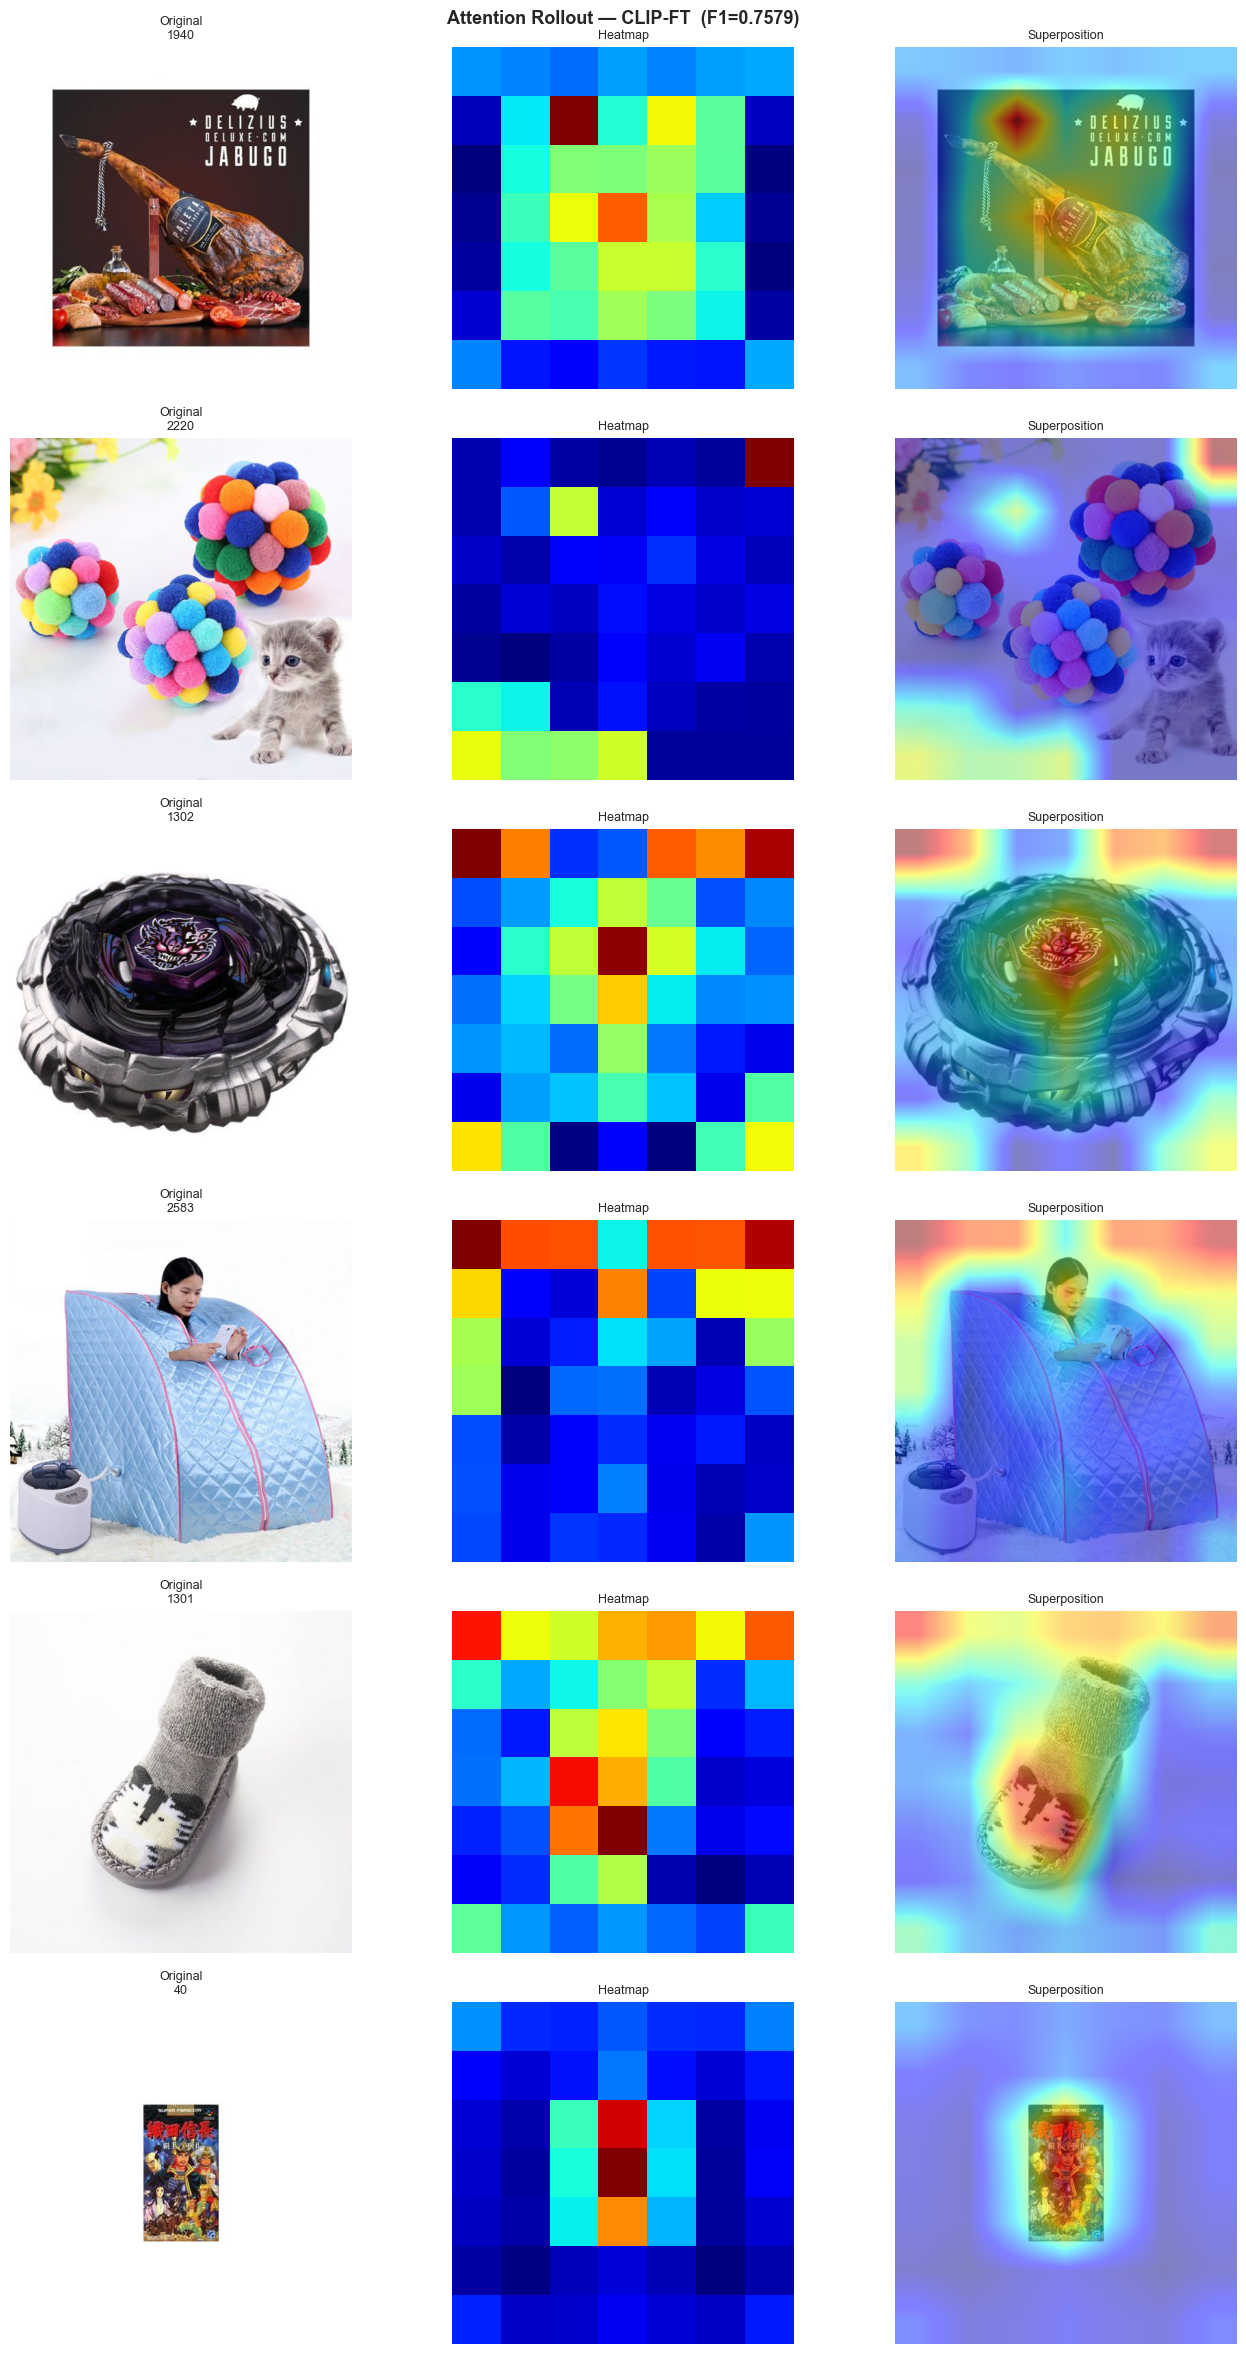

In [35]:
_resnet_path = CFG["models_dir"] / "resnet50_ft.pth"
_dino_path   = CFG["models_dir"] / "dino_ft_best.pth"
_clip_path   = CFG["models_dir"] / "clip_ft_best.pth"

def _get_f1(model, loader):
    _, yl, yp = eval_model(model, loader)
    return f1_score(yl, yp.argmax(1), average="weighted")

_models = {}

if _resnet_path.exists():
    _r = ResNet50Classifier(CFG["n_classes"]).to(device)
    _r.load_state_dict(torch.load(_resnet_path, map_location=device))
    _r.eval()
    _f1_r = _get_f1(_r, val_loader)
    _viz_r = GradCAM(_r, _r.backbone.layer4[-1])
    _models["resnet50"] = dict(
        transform=transform_eval,
        label=f"GradCAM — ResNet50  (F1={_f1_r:.4f})",
        get_cam=lambda img_t, cls, v=_viz_r: v.generate(
            img_t, class_idx=cls, forward_fn=lambda x: v.model(x)
        ),
    )
    print(f"ResNet50   F1={_f1_r:.4f}")

if _dino_path.exists():
    try:
        _dino_m = dino_ft
    except NameError:
        from transformers import AutoModel
        _bb = AutoModel.from_pretrained(CFG["dino_model"])
        for p in _bb.parameters(): p.requires_grad = False
        _dino_m = DINOv2Classifier(_bb, CFG["n_classes"]).to(device)
    _dino_m.load_state_dict(torch.load(_dino_path, map_location=device))
    _dino_m.eval()
    _vl_d = DataLoader(
        ImageDataset(val_df, CFG["split_dir"] / "val", y_val, transform_eval),
        batch_size=CFG["ft_batch"] * 2, shuffle=False, num_workers=0,
    )
    _f1_d = _get_f1(_dino_m, _vl_d)
    _viz_d = DINOAttnViz(_dino_m)
    _models["dino_ft"] = dict(
        transform=transform_eval,
        label=f"Self-Attention CLS — DINOv2-FT  (F1={_f1_d:.4f})",
        get_cam=lambda img_t, cls, v=_viz_d: v.generate(img_t),
    )
    print(f"DINOv2-FT  F1={_f1_d:.4f}")

if _clip_path.exists():
    try:
        _clip_m = clip_ft
    except NameError:
        from open_clip import create_model_and_transforms
        _cb, _, _ = create_model_and_transforms("ViT-B-32", pretrained="laion2b_s34b_b79k")
        _clip_m = CLIPFTClassifier(_cb.visual.to(device), CFG["n_classes"]).to(device)
    _clip_m.load_state_dict(torch.load(_clip_path, map_location=device))
    _clip_m.eval()
    _vl_c = DataLoader(
        ImageDataset(val_df, CFG["split_dir"] / "val", y_val, transform_clip_eval),
        batch_size=CFG["ft_batch"] * 2, shuffle=False, num_workers=0,
    )
    _f1_c = _get_f1(_clip_m, _vl_c)
    _viz_c = CLIPRollout(_clip_m)
    _models["clip_ft"] = dict(
        transform=transform_clip_eval,
        label=f"Attention Rollout — CLIP-FT  (F1={_f1_c:.4f})",
        get_cam=lambda img_t, cls, v=_viz_c: v.generate(img_t),
    )
    print(f"CLIP-FT    F1={_f1_c:.4f}")

if not _models:
    raise RuntimeError("Aucun modele .pth trouve.")

with open(CFG["models_dir"] / "label_encoder.pkl", "rb") as f:
    le = pickle.load(f)

N_CLASSES_SHOW = 6
rng = np.random.default_rng(42)
sample_classes = rng.choice(CFG["n_classes"], N_CLASSES_SHOW, replace=False)

for model_name, info in _models.items():
    fig, axes = plt.subplots(N_CLASSES_SHOW, 3, figsize=(14, N_CLASSES_SHOW * 4))
    fig.suptitle(info["label"], fontsize=13, fontweight="bold")

    for row, cls_idx in enumerate(sample_classes):
        idx_in_val = np.where(y_val == cls_idx)[0][0]
        img_path = CFG["split_dir"] / "val" / str(val_df.iloc[idx_in_val]["image_name"])
        try:
            orig_img   = Image.open(img_path).convert("RGB")
            img_tensor = info["transform"](orig_img)
            cam        = info["get_cam"](img_tensor, int(cls_idx))
            overlay    = overlay_gradcam(orig_img, cam)
            axes[row, 0].imshow(orig_img)
            axes[row, 0].set_title(f"Original\n{le.classes_[cls_idx]}", fontsize=9)
            axes[row, 1].imshow(cam, cmap="jet")
            axes[row, 1].set_title("Heatmap", fontsize=9)
            axes[row, 2].imshow(overlay)
            axes[row, 2].set_title("Superposition", fontsize=9)
        except Exception as e:
            for ax in axes[row]:
                ax.text(0.5, 0.5, str(e), ha="center", va="center", transform=ax.transAxes)
        for ax in axes[row]:
            ax.axis("off")

    plt.tight_layout()
    save_fig(f"viz_{model_name}.png")
    plt.show()


---
## 10. Export OOF Images — Meilleur modèle

In [27]:
# Selection du meilleur modele image frozen (DINOv2 ou CLIP)
bench_img_df = pd.DataFrame(bench_img).sort_values('F1_Test', ascending=False)
print('\n=== BENCHMARK IMAGE (frozen) ===')
print(bench_img_df.to_string(index=False))

best_img_config = bench_img_df.iloc[0]['Config']
print(f'\nMeilleur modele frozen : {best_img_config}')

P_img_oof = np.load(str(CFG['processed'] / f'P_{best_img_config}_oof_train.npy'))
P_img_val = np.load(str(CFG['processed'] / f'P_{best_img_config}_val.npy'))
P_img_tst = np.load(str(CFG['processed'] / f'P_{best_img_config}_test.npy'))

# Alias standard pour le notebook 5
np.save(CFG['processed'] / 'P_image_oof_train.npy', P_img_oof)
np.save(CFG['processed'] / 'P_image_val.npy',       P_img_val)
np.save(CFG['processed'] / 'P_image_test.npy',      P_img_tst)

f1_img = f1_score(y_test, P_img_tst.argmax(1), average='weighted')
print(f'F1 Test image : {f1_img:.4f}')
print('OOF image sauvegardees sous P_image_*.npy')


=== BENCHMARK IMAGE (frozen) ===
      Config  F1_OOF  F1_Val  F1_Test
 I2_clip_mlp  0.7430  0.7577   0.7486
I3_dino_crop  0.6942  0.7131   0.7073
 I1_dino_mlp  0.6901  0.7092   0.7051

Meilleur modele frozen : I2_clip_mlp
F1 Test image : 0.7486
OOF image sauvegardees sous P_image_*.npy


---
## 11. Récapitulatif

In [28]:
print('=' * 65)
print('  NOTEBOOK 4 — BILAN EXPERIENCES IMAGES')
print('=' * 65)
print()
print(bench_img_df.to_string(index=False))
print()
print('FICHIERS OOF GENERES (pour notebook 5) :')
for p in [
    CFG['processed'] / 'P_image_oof_train.npy',
    CFG['processed'] / 'P_image_val.npy',
    CFG['processed'] / 'P_image_test.npy',
    CFG['models_dir'] / 'resnet50_ft.pth',
    CFG['models_dir'] / 'dino_ft_best.pth',
]:
    print(f'  [{"OK" if p.exists() else "MANQUANT"}] {p.name}')
print()
print('PROCHAIN NOTEBOOK : 05_stacking_final.ipynb')

  NOTEBOOK 4 — BILAN EXPERIENCES IMAGES

      Config  F1_OOF  F1_Val  F1_Test
 I2_clip_mlp  0.7430  0.7577   0.7486
I3_dino_crop  0.6942  0.7131   0.7073
 I1_dino_mlp  0.6901  0.7092   0.7051

FICHIERS OOF GENERES (pour notebook 5) :
  [OK] P_image_oof_train.npy
  [OK] P_image_val.npy
  [OK] P_image_test.npy
  [OK] resnet50_ft.pth
  [OK] dino_ft_best.pth

PROCHAIN NOTEBOOK : 05_stacking_final.ipynb
